
**Soal 5 - Optimasi Produksi Media Agar (Programming Linear)**

**Variabel Keputusan:**
* $x$ = Liter Media Agar Cokelat
* $y$ = Liter Media Agar Hijau

**Fungsi Tujuan (Maksimumkan):**
* Z = 25.000x + 30.000y

**Kendala:**
* **Nutrisi organik:** $2x + y \le 16$ gram
* **Hormon pertumbuhan:** $x + 3y \le 18$ gram
* **Non-negatif:** $x, y \ge 0$


# Import Library

In [ ]:
import itertools
import numpy as np
import matplotlib
# matplotlib.use("Agg")
import matplotlib.pyplot as plt
import itertools
from scipy.optimize import linprog

# Data

In [ ]:
c = np.array([25000, 30000])          # koefisien keuntungan
A = np.array([[2, 1],                 # nutrisi organik
              [1, 3]])                # hormon pertumbuhan
b = np.array([16, 18])                # ketersediaan bahan

# Titik Sudut

In [ ]:
garis = [(A[0], b[0]), (A[1], b[1]),
         (np.array([1, 0]), 0),
         (np.array([0, 1]), 0)]

def layak(p, tol=1e-9):
    return (p[0] >= -tol and p[1] >= -tol and np.all(A @ p <= b + tol))

titik_sudut = []
for (a1, r1), (a2, r2) in itertools.combinations(garis, 2):
    M = np.array([a1, a2], dtype=float)
    if abs(np.linalg.det(M)) < 1e-12:
        continue
    p = np.linalg.solve(M, [r1, r2])
    if layak(p) and not any(np.allclose(p, q) for q in titik_sudut):
        titik_sudut.append(p)

print(" " * 55)
print("METODE TITIK SUDUT")
print(" " * 55)
print(f"{'Titik (x, y)':<18}{'Z = 25.000x + 30.000y':>30}")
hasil = []
for p in sorted(titik_sudut, key=lambda t: (t[0], t[1])):
    z = c @ p
    hasil.append((p, z))
    print(f"({p[0]:5.2f}, {p[1]:5.2f})      Rp {z:>15,.0f}")

p_opt, z_opt = max(hasil, key=lambda t: t[1])
print(f"\nOptimal: x = {p_opt[0]:.2f} liter (Cokelat), "
      f"y = {p_opt[1]:.2f} liter (Hijau)")
print(f"Keuntungan maksimum = Rp {z_opt:,.0f}")

                                                       
METODE TITIK SUDUT
                                                       
Titik (x, y)               Z = 25.000x + 30.000y
( 0.00,  0.00)      Rp               0
( 0.00,  6.00)      Rp         180,000
( 6.00,  4.00)      Rp         270,000
( 8.00,  0.00)      Rp         200,000

Optimal: x = 6.00 liter (Cokelat), y = 4.00 liter (Hijau)
Keuntungan maksimum = Rp 270,000


# Dilakukan Verivikasi Dengan Scipy Linprog

In [ ]:
res = linprog(-c, A_ub=A, b_ub=b, bounds=[(0, None), (0, None)],
              method="highs")
print("VERIFIKASI SCIPY linprog")
print(" " * 55)
print(f"x = {res.x[0]:.2f}, y = {res.x[1]:.2f}, "
      f"Z maks = Rp {-res.fun:,.0f}")

pakai = A @ res.x
print(f"Nutrisi organik terpakai : {pakai[0]:.1f} / {b[0]} gram")
print(f"Hormon pertumbuhan terpakai: {pakai[1]:.1f} / {b[1]} gram")

VERIFIKASI SCIPY linprog
                                                       
x = 6.00, y = 4.00, Z maks = Rp 270,000
Nutrisi organik terpakai : 16.0 / 16 gram
Hormon pertumbuhan terpakai: 18.0 / 18 gram


# Grafik

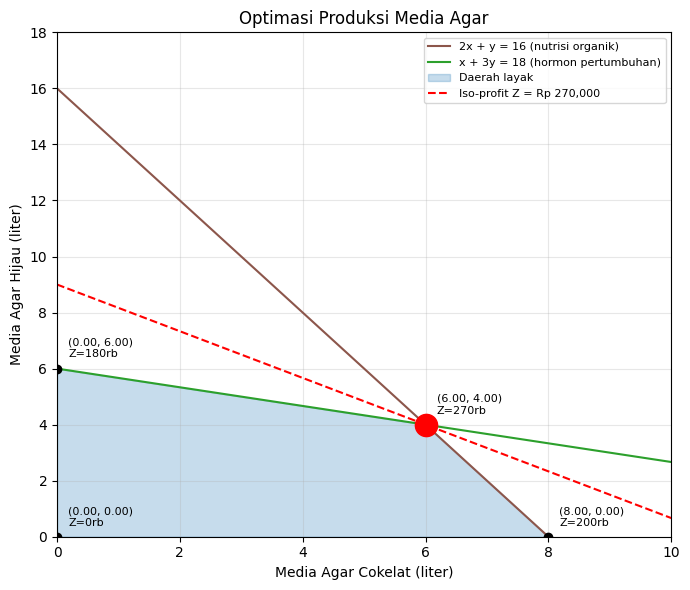

In [ ]:
c = np.array([25000, 30000])   # Fungsi tujuan: Z = 25000x + 30000y
A = np.array([[2, 1], [1, 3]]) # Koefisien kendala
b = np.array([16, 18])         # Batas kendala

garis = [(A[0], b[0]), (A[1], b[1]), (np.array([1, 0]), 0), (np.array([0, 1]), 0)]

def layak(p, tol=1e-9):
    return (p[0] >= -tol and p[1] >= -tol and np.all(A @ p <= b + tol))

titik_sudut = []
for (a1, r1), (a2, r2) in itertools.combinations(garis, 2):
    M = np.array([a1, a2], dtype=float)
    if abs(np.linalg.det(M)) < 1e-12: continue
    p = np.linalg.solve(M, [r1, r2])
    if layak(p) and not any(np.allclose(p, q) for q in titik_sudut):
        titik_sudut.append(p)

hasil = [(p, c @ p) for p in sorted(titik_sudut, key=lambda t: (t[0], t[1]))]
p_opt, z_opt = max(hasil, key=lambda t: t[1])

x = np.linspace(0, 10, 400)
y1 = 16 - 2 * x
y2 = (18 - x) / 3

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(x, y1, label="2x + y = 16 (nutrisi organik)", color="tab:brown")
ax.plot(x, y2, label="x + 3y = 18 (hormon pertumbuhan)", color="tab:green")

y_batas = np.minimum(y1, y2)
ax.fill_between(x, 0, np.maximum(y_batas, 0), where=(y_batas >= 0),
                alpha=0.25, color="tab:blue", label="Daerah layak")

for p, z in hasil:
    ax.plot(*p, "ko")
    ax.annotate(f"({p[0]:.2f}, {p[1]:.2f})\nZ={z / 1000:.0f}rb",
                xy=p, xytext=(8, 8), textcoords="offset points", fontsize=8)

y_iso = (z_opt - c[0] * x) / c[1]
ax.plot(x, y_iso, "r--", label=f"Iso-profit Z = Rp {z_opt:,.0f}")
ax.plot(*p_opt, "ro", markersize=16)

ax.set_xlim(0, 10)
ax.set_ylim(0, 18)
ax.set_xlabel("Media Agar Cokelat (liter)")
ax.set_ylabel("Media Agar Hijau (liter)")
ax.set_title("Optimasi Produksi Media Agar")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()